# Group 8 - Forest Cover Type classification

**Question:** Can a dense neural network predict one of seven forest cover types
from terrain, soil and wilderness-area attributes?

This notebook contains the complete data, training and evaluation workflow.
The study uses one fixed split and nine runs: the taught baseline, six
one-factor hyperparameter variants, a class-weight comparison, and dropout.
We select by validation macro-F1, with validation accuracy and loss retained
for the assignment. The final test section evaluates the frozen winner once.

**Sources:** [UCI dataset](https://archive.ics.uci.edu/dataset/31/covertype),
[original codebook](https://archive.ics.uci.edu/ml/machine-learning-databases/covtype/covtype.info),
and the supplied Group 8 assignment brief.

**AI assistance:** An AI assistant prepared the research, code, experiment
execution, analysis and report draft. Group members must review the code,
understand the results, add their names/roles, and follow the instructor's
AI-use policy. No individual contributions or private peer ratings are claimed.

**Reruns:** Completed runs are loaded only when their saved signatures match.
The final test block loads saved final results on a normal rerun. Do not change
the model after observing test results. A new study needs a new evaluation
protocol, not deletion of the old test evidence.

In [1]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("OMP_NUM_THREADS", "2")

import gc
import hashlib
import importlib.metadata
import json
import platform
import shutil
import time
from datetime import datetime, timezone, timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import display, Markdown
from sklearn.datasets import fetch_covtype
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             classification_report, confusion_matrix, f1_score)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

ROOT = Path.cwd()
assert (ROOT / "Group8_Finals_Project.pdf").exists(), "Open this notebook from the project folder."
ART = ROOT / "artifacts"
FIG = ROOT / "figures"
ART.mkdir(exist_ok=True)
FIG.mkdir(exist_ok=True)
SEED = 42
MAX_EPOCHS = 50
SAMPLE_SIZE = None  # None means all 581,012 rows. Keep fixed for the study.
SOURCE_SHA256 = "130d6ef79c6970329838149f609668a4a473e60aeaf997c90b6ebf0089497373"
CLASS_NAMES = ["Spruce/Fir", "Lodgepole Pine", "Ponderosa Pine",
               "Cottonwood/Willow", "Aspen", "Douglas-fir", "Krummholz"]
MANILA = timezone(timedelta(hours=8))
tf.config.threading.set_intra_op_parallelism_threads(2)
tf.config.threading.set_inter_op_parallelism_threads(1)
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 180,
                     "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False})

def now():
    return datetime.now(MANILA).isoformat(timespec="seconds")

def save_json(path, value):
    """Replace a small JSON record atomically, avoiding half-written progress."""
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False), encoding="utf-8")
    temporary.replace(path)

def digest_array(array):
    return hashlib.sha256(np.ascontiguousarray(array).tobytes()).hexdigest()

def digest_file(path):
    with path.open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()

versions = {name: importlib.metadata.version(name) for name in
            ["tensorflow", "keras", "numpy", "pandas", "scikit-learn", "matplotlib"]}
environment = {"python": platform.python_version(), "platform": platform.platform(),
               "processor": platform.processor(), "packages": versions,
               "devices": [str(d) for d in tf.config.list_physical_devices()],
               "intra_threads": 2, "inter_threads": 1, "deterministic_ops": True,
               "seed": SEED, "steps_per_execution": 32}
save_json(ART / "environment.json", environment)
display(pd.Series(versions, name="version").to_frame())
print("Devices:", environment["devices"])

,version
tensorflow,2.21.0
keras,3.15.1
numpy,2.5.4
pandas,3.1.1
scikit-learn,1.9.1
matplotlib,3.11.2


Devices: ["PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')"]


## Step 1 - Explore the data

One row represents a 30 x 30 metre cell in one of four Colorado wilderness
areas. Inputs describe the land; the label describes its forest cover type.
There are ten quantitative columns and 44 existing binary indicators
(four wilderness areas and forty soil types). The target is separate from
the 54 inputs. This is tabular classification, not image recognition.

The source reports no missing values. We check the loaded arrays, labels,
indicator values and row hashes rather than assuming the download is correct.

In [2]:
raw = fetch_covtype(data_home=str(ROOT / "data"))
feature_names = list(raw.feature_names)
X_raw = raw.data.astype("float32")
y = (raw.target - 1).astype("int32")
row_ids = np.arange(len(y), dtype="int64")
del raw
gc.collect()
assert X_raw.shape == (581012, 54)
assert np.isfinite(X_raw).all()
assert np.array_equal(np.unique(y), np.arange(7))
assert np.isin(X_raw[:, 10:], [0, 1]).all()
assert (X_raw[:, 10:14].sum(axis=1) == 1).all()
assert (X_raw[:, 14:54].sum(axis=1) == 1).all()

feature_hashes = pd.util.hash_pandas_object(pd.DataFrame(X_raw), index=False).to_numpy()
unique_feature_rows = int(np.unique(feature_hashes).size)
data_quality = {"rows": int(len(y)), "features": 54, "classes": 7,
                "missing_or_nonfinite_values": 0, "binary_indicators_valid": True,
                "repeated_feature_rows_by_64bit_hash": int(len(y) - unique_feature_rows),
                "note": "Row hashes detect repeated feature vectors, not physical cell identities; 64-bit hash collisions are possible."}
class_counts = pd.DataFrame({"original_id": np.arange(1, 8), "model_id": np.arange(7),
                            "cover_type": CLASS_NAMES,
                            "full_dataset_count": np.bincount(y, minlength=7)})
class_counts["share_percent"] = 100 * class_counts.full_dataset_count / len(y)
assert class_counts.full_dataset_count.tolist() == [211840, 283301, 35754, 2747, 9493, 17367, 20510]
class_counts.to_csv(ART / "class_counts.csv", index=False)
print("Shape:", X_raw.shape, "Target classes:", np.unique(y))
display(class_counts.round(4))
display(pd.DataFrame(X_raw[:5], columns=feature_names))
display(pd.Series(data_quality, name="value").to_frame())

Shape: (581012, 54) Target classes: [0 1 2 3 4 5 6]


,original_id,model_id,cover_type,full_dataset_count,share_percent
0,1,0,Spruce/Fir,211840,36.4605
1,2,1,Lodgepole Pine,283301,48.7599
2,3,2,Ponderosa Pine,35754,6.1537
3,4,3,Cottonwood/Willow,2747,0.4728
4,5,4,Aspen,9493,1.6339
5,6,5,Douglas-fir,17367,2.9891
6,7,6,Krummholz,20510,3.5300


,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type_30,Soil_Type_31,Soil_Type_32,Soil_Type_33,Soil_Type_34,Soil_Type_35,Soil_Type_36,Soil_Type_37,Soil_Type_38,Soil_Type_39
0,2596.0,51.0,3.0,258.0,0.0,510.0,221.0,232.0,148.0,6279.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2590.0,56.0,2.0,212.0,-6.0,390.0,220.0,235.0,151.0,6225.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2804.0,139.0,9.0,268.0,65.0,3180.0,234.0,238.0,135.0,6121.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2785.0,155.0,18.0,242.0,118.0,3090.0,238.0,238.0,122.0,6211.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2595.0,45.0,2.0,153.0,-1.0,391.0,220.0,234.0,150.0,6172.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


,value
rows,581012
features,54
classes,7
missing_or_nonfinite_values,0
binary_indicators_valid,True
repeated_feature_rows_by_64bit_hash,0
note,"Row hashes detect repeated feature vectors, no..."


,position,feature,meaning,unit,standardize
0,0,Elevation,Elevation,metres,True
1,1,Aspect,Slope direction,degrees azimuth,True
2,2,Slope,Slope angle,degrees,True
3,3,Horizontal_Distance_To_Hydrology,Horizontal distance to surface water,metres,True
4,4,Vertical_Distance_To_Hydrology,Vertical distance to surface water,metres,True
5,5,Horizontal_Distance_To_Roadways,Horizontal distance to roads,metres,True
6,6,Hillshade_9am,Summer-solstice hillshade at 9am,0-255 index,True
7,7,Hillshade_Noon,Summer-solstice hillshade at noon,0-255 index,True
8,8,Hillshade_3pm,Summer-solstice hillshade at 3pm,0-255 index,True
9,9,Horizontal_Distance_To_Fire_Points,Horizontal distance to wildfire ignition points,metres,True


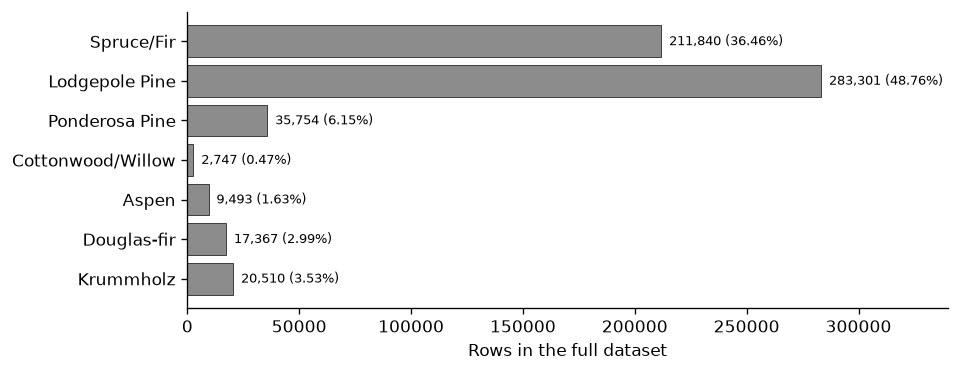

Two largest classes: 85.22% of rows.


In [3]:
units = ["metres", "degrees azimuth", "degrees", "metres", "metres", "metres",
         "0-255 index", "0-255 index", "0-255 index", "metres"]
meanings = ["Elevation", "Slope direction", "Slope angle", "Horizontal distance to surface water",
            "Vertical distance to surface water", "Horizontal distance to roads",
            "Summer-solstice hillshade at 9am", "Summer-solstice hillshade at noon",
            "Summer-solstice hillshade at 3pm", "Horizontal distance to wildfire ignition points"]
wilderness_names = ["Rawah", "Neota", "Comanche Peak", "Cache la Poudre"]
soil_codes = [2702,2703,2704,2705,2706,2717,3501,3502,4201,4703,4704,4744,4758,5101,5151,
              6101,6102,6731,7101,7102,7103,7201,7202,7700,7701,7702,7709,7710,7745,7746,
              7755,7756,7757,7790,8703,8707,8708,8771,8772,8776]
dictionary = []
for i, name in enumerate(feature_names):
    if i < 10:
        meaning, unit = meanings[i], units[i]
    elif i < 14:
        meaning, unit = "Wilderness membership: " + wilderness_names[i - 10], "0/1"
    else:
        meaning, unit = f"Soil membership: USFS ecological landtype {soil_codes[i - 14]}", "0/1"
    dictionary.append({"position": i, "feature": name, "meaning": meaning,
                       "unit": unit, "standardize": i < 10})
dictionary = pd.DataFrame(dictionary)
dictionary.to_csv(ART / "feature_dictionary.csv", index=False)
display(dictionary)

fig, ax = plt.subplots(figsize=(8.1, 3.2))
bars = ax.barh(CLASS_NAMES, class_counts.full_dataset_count, color="0.55", edgecolor="0.15", linewidth=0.5)
ax.invert_yaxis()
ax.set_xlabel("Rows in the full dataset")
ax.set_xlim(0, 340000)
for bar, count, share in zip(bars, class_counts.full_dataset_count, class_counts.share_percent):
    ax.text(count + 3500, bar.get_y() + bar.get_height()/2, f"{count:,} ({share:.2f}%)", va="center", fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "Group8_Class_Counts.png", bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Two largest classes: {class_counts.share_percent.iloc[:2].sum():.2f}% of rows.")

## Step 2 - Preprocess and freeze the split

We reserve 20% with stratification, then split that reserve equally into
validation and test. Seeds 42 and 43 fix those two operations. We fit the
scaler on training rows only, standardize columns 0-9, and preserve the
44 indicator columns. We leave validation and test at their natural class
proportions. R7 tests training-only class weights; the baseline remains
unweighted so the effect of weighting can be measured.

The study uses the full dataset if the runtime pilot permits it. Any optional
sample must be fixed before the assessed experiment family. Split IDs and
source hashes identify this study; test outcomes do not influence the split.

In [4]:
if SAMPLE_SIZE is not None:
    row_ids, _ = train_test_split(row_ids, train_size=SAMPLE_SIZE, stratify=y, random_state=SEED)
train_ids, reserve_ids = train_test_split(row_ids, test_size=0.2, stratify=y[row_ids], random_state=42)
val_ids, test_ids = train_test_split(reserve_ids, test_size=0.5, stratify=y[reserve_ids], random_state=43)
assert len(set(train_ids) & set(val_ids)) == 0
assert len(set(train_ids) & set(test_ids)) == 0
assert len(set(val_ids) & set(test_ids)) == 0
assert len(train_ids) + len(val_ids) + len(test_ids) == len(row_ids)
for ids in (train_ids, val_ids, test_ids):
    assert (np.bincount(y[ids], minlength=7) > 0).all()

cross_feature_hashes = {
    "train_validation": int(np.intersect1d(feature_hashes[train_ids], feature_hashes[val_ids]).size),
    "train_test": int(np.intersect1d(feature_hashes[train_ids], feature_hashes[test_ids]).size),
    "validation_test": int(np.intersect1d(feature_hashes[val_ids], feature_hashes[test_ids]).size)}
data_quality["shared_feature_hashes_between_splits"] = cross_feature_hashes
save_json(ART / "data_quality.json", data_quality)
split_counts = class_counts[["model_id", "cover_type"]].copy()
for name, ids in [("train", train_ids), ("validation", val_ids), ("test", test_ids)]:
    split_counts[name] = np.bincount(y[ids], minlength=7)
split_counts.to_csv(ART / "split_class_counts.csv", index=False)
display(split_counts)
print("Split sizes:", len(train_ids), len(val_ids), len(test_ids))
print("Repeated-feature hash overlap:", cross_feature_hashes)

scaler = StandardScaler().fit(X_raw[train_ids, :10])
def transform(ids):
    result = X_raw[ids].copy()
    result[:, :10] = scaler.transform(result[:, :10])
    return result
X_train, y_train = transform(train_ids), y[train_ids]
X_val, y_val = transform(val_ids), y[val_ids]
assert np.max(np.abs(X_train[:, :10].mean(axis=0))) < 1e-3
assert np.allclose(X_train[:, :10].std(axis=0), 1, atol=1e-3)
assert np.array_equal(X_train[:, 10:], X_raw[train_ids, 10:])
weights = compute_class_weight("balanced", classes=np.arange(7), y=y_train)
class_weight = {int(i): float(w) for i, w in enumerate(weights)}
display(pd.DataFrame({"cover_type": CLASS_NAMES, "R7_training_weight": weights}))

BASE = {"units": [50, 50], "activation": "relu", "batch_size": 100,
        "learning_rate": 0.001, "patience": 2, "dropout": 0.0, "class_weight": False}
RUNS = [
    ("R0", "Baseline", {}),
    ("R1", "Width: 100-100", {"units": [100, 100]}),
    ("R2", "Depth: 50-50-50", {"units": [50, 50, 50]}),
    ("R3", "Activation: tanh", {"activation": "tanh"}),
    ("R4", "Batch size: 500", {"batch_size": 500}),
    ("R5", "Learning rate: 0.0003", {"learning_rate": 0.0003}),
    ("R6", "Patience: 5", {"patience": 5}),
    ("R7", "Balanced training weights", {"class_weight": True}),
    ("R8", "Dropout: 0.2", {"dropout": 0.2}),
]
for run_id, description, changes in RUNS[1:]:
    assert len(changes) == 1, f"{run_id} must change exactly one baseline setting."

study_spec = {"protocol": "group8-full-data-v1", "source_sha256": SOURCE_SHA256,
              "data_sha256": digest_array(X_raw), "target_sha256": digest_array(y),
              "split_hashes": {"train": digest_array(train_ids), "validation": digest_array(val_ids), "test": digest_array(test_ids)},
              "sizes": {"train": len(train_ids), "validation": len(val_ids), "test": len(test_ids)},
              "sample_size": SAMPLE_SIZE, "seed": SEED, "max_epochs": MAX_EPOCHS,
              "baseline": BASE, "runs": RUNS, "environment": environment,
              "selection": "macro_f1 desc, accuracy desc, loss asc, parameters asc, run_id asc"}
study_id = hashlib.sha256(json.dumps(study_spec, sort_keys=True).encode()).hexdigest()
manifest_path = ART / "study_manifest.json"
if manifest_path.exists():
    previous = json.loads(manifest_path.read_text(encoding="utf-8"))
    assert previous["study_id"] == study_id, "Study inputs changed. Preserve existing evidence; use a separately planned study."
else:
    save_json(manifest_path, {"study_id": study_id, "created": now(), **study_spec})
np.savez_compressed(ART / "split_indices.npz", train=train_ids, validation=val_ids, test=test_ids)
np.savez(ART / "scaler.npz", mean=scaler.mean_, scale=scaler.scale_, var=scaler.var_)
save_json(ART / "feature_and_class_map.json", {"features": feature_names, "classes": CLASS_NAMES,
                                           "original_labels": list(range(1, 8)), "model_labels": list(range(7))})
print("Frozen study ID:", study_id)

,model_id,cover_type,train,validation,test
0,0,Spruce/Fir,169472,21184,21184
1,1,Lodgepole Pine,226640,28330,28331
2,2,Ponderosa Pine,28603,3575,3576
3,3,Cottonwood/Willow,2198,275,274
4,4,Aspen,7594,950,949
5,5,Douglas-fir,13894,1736,1737
6,6,Krummholz,16408,2051,2051


Split sizes: 464809 58101 58102
Repeated-feature hash overlap: {'train_validation': 0, 'train_test': 0, 'validation_test': 0}


,cover_type,R7_training_weight
0,Spruce/Fir,0.391813
1,Lodgepole Pine,0.292981
2,Ponderosa Pine,2.321480
3,Cottonwood/Willow,30.209866
4,Aspen,8.743914
5,Douglas-fir,4.779134
6,Krummholz,4.046885


Frozen study ID: af27c446d15d7c2e854bc8f56e876bb5fbaac8e1c5078bb4adafd606750a87cb


## Step 3 - Build and train the baseline

The baseline has 54 inputs, two 50-unit ReLU hidden layers and seven softmax
outputs: 5,657 trainable parameters. Integer labels 0-6 match sparse
categorical cross-entropy. Adam starts at learning rate 0.001.

EarlyStopping monitors validation loss with patience 2 and explicitly restores
the best weights. The shared epoch cap is 50. We report the validation metrics
of that restored checkpoint, not a mixture of different epochs. Models,
optimizers and callbacks start fresh for each run. CPU threads and compiled
execution settings stay fixed across the experiment family.

In [5]:
def make_dataset(x, labels=None, batch_size=1024, training=False):
    values = x if labels is None else (x, labels)
    dataset = tf.data.Dataset.from_tensor_slices(values)
    if training:
        dataset = dataset.shuffle(len(x), seed=SEED, reshuffle_each_iteration=True)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 2
    options.threading.max_intra_op_parallelism = 1
    return dataset.batch(batch_size).with_options(options).prefetch(1)

def build_model(config):
    model = tf.keras.Sequential([tf.keras.Input(shape=(54,))])
    for units in config["units"]:
        model.add(tf.keras.layers.Dense(units, activation=config["activation"]))
        if config["dropout"]:
            model.add(tf.keras.layers.Dropout(config["dropout"]))
    model.add(tf.keras.layers.Dense(7, activation="softmax"))
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=config["learning_rate"]),
                  loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
                  metrics=["accuracy"], steps_per_execution=32)
    return model

def summarize_predictions(labels, probabilities):
    predicted = probabilities.argmax(axis=1)
    return {"accuracy": float(accuracy_score(labels, predicted)),
            "macro_f1": float(f1_score(labels, predicted, average="macro", zero_division=0)),
            "balanced_accuracy": float(balanced_accuracy_score(labels, predicted))}

class Progress(tf.keras.callbacks.Callback):
    def __init__(self, run_id):
        super().__init__()
        self.run_id = run_id
    def on_train_begin(self, logs=None):
        self.start = time.perf_counter()
    def on_epoch_end(self, epoch, logs=None):
        record = {"stage": "training", "run_id": self.run_id, "epoch": epoch + 1,
                  "max_epochs": MAX_EPOCHS, "updated": now(),
                  "elapsed_seconds": time.perf_counter() - self.start,
                  "metrics": {k: float(v) for k, v in logs.items()}}
        save_json(ART / "progress.json", record)

def train_run(run_id, description, changes):
    config = {**BASE, **changes}
    run_dir = ART / "runs" / run_id
    run_dir.mkdir(parents=True, exist_ok=True)
    signature = hashlib.sha256(json.dumps({"study_id": study_id, "config": config}, sort_keys=True).encode()).hexdigest()
    record_path = run_dir / "metrics.json"
    if record_path.exists():
        record = json.loads(record_path.read_text(encoding="utf-8"))
        assert record["signature"] == signature
        assert digest_file(run_dir / "model.keras") == record["model_sha256"]
        print(run_id, "loaded verified saved result")
        return record
    assert not (ART / "final_test_metrics.json").exists(), "Do not train more models after the final test."
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = build_model(config)
    stopping = tf.keras.callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=config["patience"], restore_best_weights=True)
    start = time.perf_counter()
    history = model.fit(make_dataset(X_train, y_train, config["batch_size"], training=True),
                        validation_data=make_dataset(X_val, y_val), epochs=MAX_EPOCHS,
                        callbacks=[stopping, Progress(run_id)],
                        class_weight=class_weight if config["class_weight"] else None, shuffle=False, verbose=0)
    training_seconds = time.perf_counter() - start
    validation = model.evaluate(make_dataset(X_val, y_val), verbose=0, return_dict=True)
    probabilities = model.predict(make_dataset(X_val), verbose=0)
    scores = summarize_predictions(y_val, probabilities)
    assert abs(scores["accuracy"] - validation["accuracy"]) < 1e-6
    history_frame = pd.DataFrame(history.history)
    history_frame.index = np.arange(1, len(history_frame) + 1)
    history_frame.index.name = "epoch"
    history_frame.to_csv(run_dir / "history.csv")
    model.save(run_dir / "model.keras")
    selected_epoch = int(np.argmin(history.history["val_loss"]) + 1)
    record = {"run_id": run_id, "reference": "" if run_id == "R0" else "R0",
              "description": description, "config": config, "signature": signature,
              "study_id": study_id, "epochs_run": len(history_frame), "selected_epoch": selected_epoch,
              "val_loss": float(validation["loss"]), "val_accuracy": scores["accuracy"],
              "val_macro_f1": scores["macro_f1"], "val_balanced_accuracy": scores["balanced_accuracy"],
              "training_seconds": training_seconds, "parameters": int(model.count_params()),
              "model_sha256": digest_file(run_dir / "model.keras"), "finished": now(),
              "hit_epoch_cap": len(history_frame) == MAX_EPOCHS,
              "class_weights": class_weight if config["class_weight"] else None}
    save_json(run_dir / "validation_class_report.json", classification_report(y_val, probabilities.argmax(axis=1), labels=np.arange(7), target_names=CLASS_NAMES, output_dict=True, zero_division=0))
    save_json(record_path, record)
    save_json(ART / "progress.json", {"stage": "run_complete", "run_id": run_id, "updated": now(), "record": record})
    print(f"{run_id}: {len(history_frame)} epochs; val accuracy={scores['accuracy']:.4f}; macro-F1={scores['macro_f1']:.4f}; {training_seconds:.1f}s")
    del model, probabilities
    gc.collect()
    return record

baseline_model = build_model(BASE)
assert baseline_model.count_params() == 5657
baseline_model.summary()
del baseline_model
records = [train_run(*RUNS[0])]
display(pd.DataFrame(records)[["run_id", "description", "epochs_run", "selected_epoch", "val_loss", "val_accuracy", "val_macro_f1"]])

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 50)             │         2,750 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 50)             │         2,550 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 7)              │           357 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,657 (22.10 KB)

 Trainable params: 5,657 (22.10 KB)

 Non-trainable params: 0 (0.00 B)

R0 loaded verified saved result


,run_id,description,epochs_run,selected_epoch,val_loss,val_accuracy,val_macro_f1
0,R0,Baseline,16,14,0.341694,0.857472,0.782717


## Step 4 - Run controlled experiments

Each variant changes one setting relative to R0. Width, depth, activation,
batch size, learning rate and patience form the six required changes.
R7 tests class weights and R8 tests dropout as additional comparisons.
Dropout is a bonus candidate only if the instructor did not cover it in class.
We keep the data, splits, epoch cap, seed policy and other settings fixed.

The selection rule was fixed before the runs: highest validation macro-F1,
then validation accuracy, lower validation loss, fewer parameters, and run ID.
Each score describes the weights restored at minimum validation loss.

R1 loaded verified saved result
R2 loaded verified saved result
R3 loaded verified saved result
R4 loaded verified saved result
R5 loaded verified saved result
R6 loaded verified saved result
R7 loaded verified saved result
R8 loaded verified saved result


,run_id,reference,description,epochs_run,selected_epoch,val_loss,val_accuracy,val_macro_f1,val_balanced_accuracy,training_seconds,parameters,hit_epoch_cap
0,R0,,Baseline,16,14,0.34169,0.85747,0.78272,0.75147,41.41656,5657,False
1,R1,R0,Width: 100-100,13,11,0.27934,0.88656,0.82722,0.82503,38.32050,16307,False
2,R2,R0,Depth: 50-50-50,20,18,0.28887,0.88379,0.81633,0.80407,52.54032,8207,False
3,R3,R0,Activation: tanh,34,32,0.26815,0.89313,0.82544,0.79653,77.14959,5657,False
4,R4,R0,Batch size: 500,22,20,0.36114,0.85257,0.76280,0.72981,26.78622,5657,False
5,R5,R0,Learning rate: 0.0003,42,40,0.34326,0.85869,0.77527,0.74461,92.53204,5657,False
6,R6,R0,Patience: 5,50,46,0.29011,0.88207,0.82705,0.80485,111.59219,5657,True
7,R7,R0,Balanced training weights,15,13,0.49647,0.79591,0.73526,0.87353,33.71126,5657,False
8,R8,R0,Dropout: 0.2,24,22,0.41847,0.82508,0.71140,0.66744,66.04644,5657,False


Validation-selected winner: R1 Width: 100-100


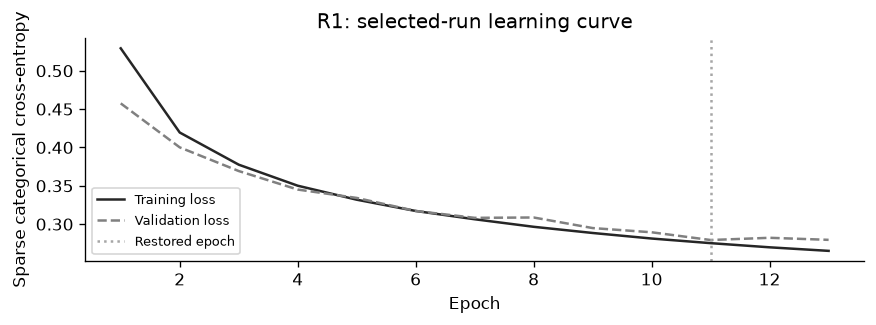

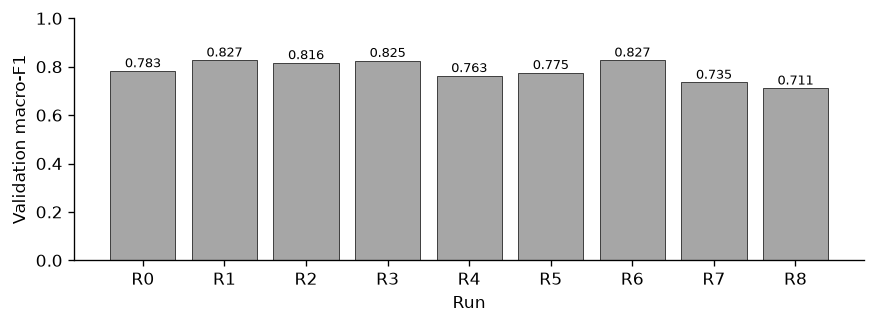

Class weighting changes training loss. If R7 wins, its weighted training loss and ordinary validation loss use different aggregate objectives; use the frozen model's ordinary accuracy for the train/validation comparison.

In [6]:
for run in RUNS[1:]:
    records.append(train_run(*run))
experiment_log = pd.DataFrame(records)
log_columns = ["run_id", "reference", "description", "epochs_run", "selected_epoch",
               "val_loss", "val_accuracy", "val_macro_f1", "val_balanced_accuracy",
               "training_seconds", "parameters", "hit_epoch_cap"]
experiment_log[log_columns].to_csv(ART / "Group8_Experiment_Log.csv", index=False)
display(experiment_log[log_columns].round(5))
ranking = experiment_log.sort_values(["val_macro_f1", "val_accuracy", "val_loss", "parameters", "run_id"],
                                   ascending=[False, False, True, True, True])
winner = records[int(ranking.index[0])]
print("Validation-selected winner:", winner["run_id"], winner["description"])

history = pd.read_csv(ART / "runs" / winner["run_id"] / "history.csv")
fig, ax = plt.subplots(figsize=(7.4, 2.8))
ax.plot(history.epoch, history.loss, color="0.15", label="Training loss", linewidth=1.5)
ax.plot(history.epoch, history.val_loss, color="0.5", linestyle="--", label="Validation loss", linewidth=1.5)
ax.axvline(winner["selected_epoch"], color="0.65", linestyle=":", label="Restored epoch")
ax.set(xlabel="Epoch", ylabel="Sparse categorical cross-entropy", title=f"{winner['run_id']}: selected-run learning curve")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "Group8_Best_Loss_Curve.png", bbox_inches="tight")
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(7.4, 2.8))
ax.bar(experiment_log.run_id, experiment_log.val_macro_f1, color="0.65", edgecolor="0.15", linewidth=0.5)
ax.set(xlabel="Run", ylabel="Validation macro-F1", ylim=(0, 1))
for i, value in enumerate(experiment_log.val_macro_f1):
    ax.text(i, value + 0.015, f"{value:.3f}", ha="center", fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "Group8_Validation_Comparison.png", bbox_inches="tight")
plt.show()
plt.close(fig)
display(Markdown("Class weighting changes training loss. If R7 wins, its weighted training loss and ordinary validation loss use different aggregate objectives; use the frozen model's ordinary accuracy for the train/validation comparison."))

## Step 5 - Freeze the model and test it once

We now freeze the winner and save its identity before accessing test outcomes.
We keep its restored weights rather than refitting on train plus validation.
That preserves the exact model selected above. The final block makes one
`model.evaluate` call on test data and saves predictions from the same model
for the required confusion matrix and wrong-example analysis.

Normal reruns load the saved final assessment. A completion record and model
hash prevent replacing it silently. An interrupted first assessment needs
investigation rather than automatic repeated testing.

In [7]:
selected_source = ART / "runs" / winner["run_id"] / "model.keras"
selected_path = ART / "Group8_Selected_Model.keras"
selection_path = ART / "selection.json"
selection = {"run_id": winner["run_id"], "study_id": study_id, "model_sha256": digest_file(selected_source),
             "rule": study_spec["selection"], "validation": {k: winner[k] for k in ["val_loss", "val_accuracy", "val_macro_f1", "selected_epoch"]},
             "config": winner["config"]}
if selection_path.exists():
    frozen = json.loads(selection_path.read_text(encoding="utf-8"))
    assert all(frozen[k] == selection[k] for k in selection)
else:
    shutil.copy2(selected_source, selected_path)
    save_json(selection_path, {**selection, "frozen_before_test": now()})
assert digest_file(selected_path) == selection["model_sha256"]
tf.keras.backend.clear_session()
selected_model = tf.keras.models.load_model(selected_path)
selected_model.summary()
frozen_scores = {}
for split_name, x_part, labels in [("train", X_train, y_train), ("validation", X_val, y_val)]:
    part_prob = selected_model.predict(make_dataset(x_part), verbose=0)
    frozen_scores[split_name] = summarize_predictions(labels, part_prob)
save_json(ART / "frozen_train_validation_metrics.json", frozen_scores)

final_path = ART / "final_test_metrics.json"
probability_path = ART / "final_test_probabilities.npz"
marker_path = ART / "final_test_started.json"
if final_path.exists():
    final_test = json.loads(final_path.read_text(encoding="utf-8"))
    assert final_test["study_id"] == study_id
    assert final_test["model_sha256"] == selection["model_sha256"]
    assert digest_file(probability_path) == final_test["probabilities_sha256"]
    saved = np.load(probability_path)
    test_probabilities = saved["probabilities"]
    assert np.array_equal(saved["row_ids"], test_ids)
    print("Loaded saved final assessment; no new test evaluation.")
else:
    assert not marker_path.exists(), "A previous test phase started but did not finish. Investigate before any further evaluation."
    save_json(marker_path, {"started": now(), "study_id": study_id, "model_sha256": selection["model_sha256"]})
    X_test = transform(test_ids)
    test_evaluation = selected_model.evaluate(make_dataset(X_test, y[test_ids]), verbose=0, return_dict=True)
    test_probabilities = selected_model.predict(make_dataset(X_test), verbose=0)
    np.savez_compressed(probability_path, row_ids=test_ids, probabilities=test_probabilities)
    final_test = {"finished": now(), "study_id": study_id, "run_id": winner["run_id"],
                  "model_sha256": selection["model_sha256"], "evaluate_calls": 1,
                  "loss": float(test_evaluation["loss"]),
                  **summarize_predictions(y[test_ids], test_probabilities),
                  "test_rows": len(test_ids), "probabilities_sha256": digest_file(probability_path)}
    assert abs(final_test["accuracy"] - test_evaluation["accuracy"]) < 1e-6
    save_json(final_path, final_test)
    del X_test
test_predicted = test_probabilities.argmax(axis=1)
predictions = pd.DataFrame({"row_id": test_ids, "true_id": y[test_ids], "predicted_id": test_predicted,
                            "true_class": np.array(CLASS_NAMES)[y[test_ids]],
                            "predicted_class": np.array(CLASS_NAMES)[test_predicted],
                            "maximum_softmax": test_probabilities.max(axis=1)})
predictions.to_csv(ART / "Group8_Test_Predictions.csv", index=False)
print(json.dumps(final_test, indent=2))

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 100)            │         5,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │        10,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 7)              │           707 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 48,923 (191.11 KB)

 Trainable params: 16,307 (63.70 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 32,616 (127.41 KB)

Loaded saved final assessment; no new test evaluation.
{
  "finished": "2026-11-06T19:15:19+08:00",
  "study_id": "af27c446d15d7c2e854bc8f56e876bb5fbaac8e1c5078bb4adafd606750a87cb",
  "run_id": "R1",
  "model_sha256": "be0ea1ae947ccbe8dbf3a2db129bfe7936c389c8f929f74fdef469b604749f77",
  "evaluate_calls": 1,
  "loss": 0.2798972427845001,
  "accuracy": 0.8875425975009467,
  "macro_f1": 0.8315095876217,
  "balanced_accuracy": 0.8324209935974342,
  "test_rows": 58102,
  "probabilities_sha256": "64005a5c37d0afcc0a543acb74e27ff7efe94d2e39e90b8b0d06d39180bba6ee"
}


## Step 6 - Explain results, errors and limits

We compare the same frozen model's inference-mode scores on training,
validation and test. Macro-F1 weights the seven class F1 scores equally;
balanced accuracy is mean class recall. Per-class recall is the fraction of
each true class predicted correctly, our definition of “accuracy for each
class.” The row-normalized confusion matrix exposes that behavior.

,accuracy,macro_f1,balanced_accuracy
split,,,
train,0.89291,0.83678,0.83660
validation,0.88656,0.82722,0.82503
test,0.88754,0.83151,0.83242


,cover_type,precision,recall,f1-score,support
0,Spruce/Fir,0.90776,0.85989,0.88318,21184.0
1,Lodgepole Pine,0.88442,0.92775,0.90556,28331.0
2,Ponderosa Pine,0.85888,0.88842,0.87340,3576.0
3,Cottonwood/Willow,0.73099,0.91241,0.81169,274.0
4,Aspen,0.73265,0.67861,0.70460,949.0
5,Douglas-fir,0.84580,0.64421,0.73137,1737.0
6,Krummholz,0.90593,0.91565,0.91077,2051.0


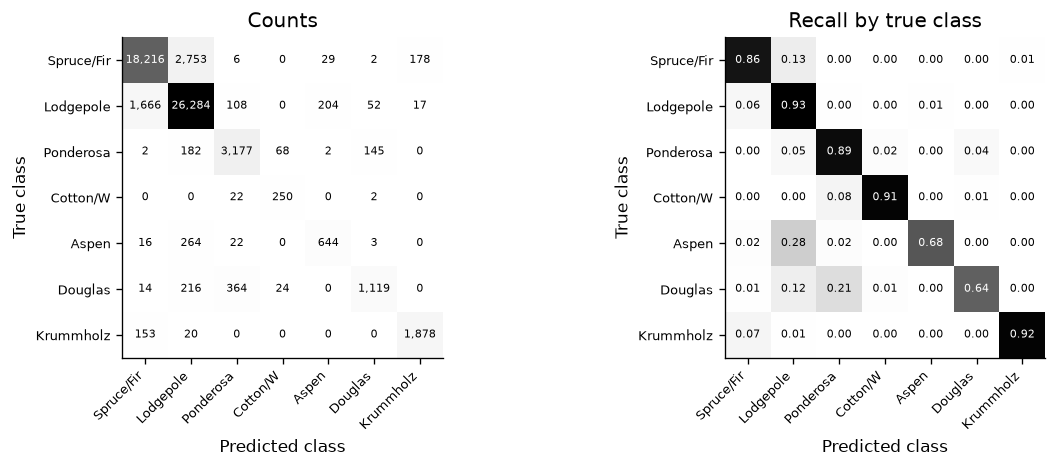

In [8]:
comparison = pd.DataFrame({**frozen_scores, "test": {k: final_test[k] for k in ["accuracy", "macro_f1", "balanced_accuracy"]}}).T
comparison.index.name = "split"
comparison.to_csv(ART / "Group8_Split_Metrics.csv")
display(comparison.round(5))
test_report = classification_report(y[test_ids], test_predicted, labels=np.arange(7), target_names=CLASS_NAMES,
                                    output_dict=True, zero_division=0)
save_json(ART / "test_class_report.json", test_report)
class_report = pd.DataFrame([{"cover_type": name, **test_report[name]} for name in CLASS_NAMES])
class_report.to_csv(ART / "Group8_Per_Class_Test_Metrics.csv", index=False)
display(class_report.round(5))
counts = confusion_matrix(y[test_ids], test_predicted, labels=np.arange(7))
normal = confusion_matrix(y[test_ids], test_predicted, labels=np.arange(7), normalize="true")
pd.DataFrame(counts, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(ART / "Group8_Confusion_Counts.csv")
pd.DataFrame(normal, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(ART / "Group8_Confusion_Normalized.csv")
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4))
short_names = ["Spruce/Fir", "Lodgepole", "Ponderosa", "Cotton/W", "Aspen", "Douglas", "Krummholz"]
for ax, matrix, title in zip(axes, [counts, normal], ["Counts", "Recall by true class"]):
    ax.imshow(matrix, cmap="Greys", vmin=0, vmax=matrix.max())
    for i in range(7):
        for j in range(7):
            label = f"{matrix[i,j]:.2f}" if title != "Counts" else f"{matrix[i,j]:,}"
            ax.text(j, i, label, ha="center", va="center", fontsize=6.5,
                    color="white" if matrix[i,j] > matrix.max()*0.5 else "black")
    ax.set_xticks(range(7), short_names, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(7), short_names, fontsize=8)
    ax.set(xlabel="Predicted class", ylabel="True class", title=title)
fig.tight_layout()
fig.savefig(FIG / "Group8_Confusion_Matrices.png", bbox_inches="tight")
plt.show()
plt.close(fig)

### Five wrong test examples

We choose the lowest-row-ID error from each available true class until five
cases, then fill any remaining places by row ID. This fixed selection policy
shows several classes without searching for the most convenient narrative.
Values below retain the source units. A high softmax score can still be wrong.
Similar terrain and under-represented classes are possible explanations, not
proven causal accounts of an individual prediction.

In [9]:
errors = predictions[predictions.true_id != predictions.predicted_id].sort_values("row_id")
chosen = errors.groupby("true_id", sort=True).head(1).sort_values("true_id").head(5)
if len(chosen) < 5:
    chosen = pd.concat([chosen, errors[~errors.row_id.isin(chosen.row_id)].head(5 - len(chosen))])
assert len(chosen) >= 5, "Fewer than five wrong cases; report this honestly to the instructor."
chosen = chosen.copy()
source_rows = X_raw[chosen.row_id.to_numpy()]
chosen["elevation_m"] = source_rows[:, 0].astype(int)
chosen["aspect_degrees"] = source_rows[:, 1].astype(int)
chosen["slope_degrees"] = source_rows[:, 2].astype(int)
chosen["horizontal_water_distance_m"] = source_rows[:, 3].astype(int)
chosen["wilderness"] = np.array(wilderness_names)[source_rows[:, 10:14].argmax(axis=1)]
chosen["soil_indicator"] = source_rows[:, 14:54].argmax(axis=1) + 1
chosen["explanation_status"] = "Hypothesis only: terrain/soil can overlap across cover classes; no causal attribution was computed."
chosen.to_csv(ART / "Group8_Five_Errors.csv", index=False)
display(chosen)

gap = frozen_scores["train"]["accuracy"] - frozen_scores["validation"]["accuracy"]
rare = class_report.sort_values("recall").iloc[0]
majority_reference = float(np.mean(y[test_ids] == int(np.argmax(np.bincount(y_train)))))
dropout_change = float(experiment_log.loc[experiment_log.run_id == "R8", "val_macro_f1"].iloc[0] - records[0]["val_macro_f1"])
weight_change = float(experiment_log.loc[experiment_log.run_id == "R7", "val_macro_f1"].iloc[0] - records[0]["val_macro_f1"])
analysis = {"selected_run": winner["run_id"], "train_validation_accuracy_gap": gap,
            "worst_recall_class": str(rare.cover_type), "worst_recall": float(rare.recall),
            "majority_class_test_reference_accuracy": majority_reference,
            "dropout_validation_macro_f1_change": dropout_change,
            "class_weight_validation_macro_f1_change": weight_change,
            "test_error_count": int(len(errors)), "accuracy_gap_interpretation": "Descriptive one-split gap, not a significance test.",
            "all_runs_single_seed": True}
save_json(ART / "analysis_summary.json", analysis)
display(Markdown(f"**Measured assessment.** {winner['run_id']} achieved test accuracy **{final_test['accuracy']:.2%}**, macro-F1 **{final_test['macro_f1']:.4f}**, and balanced accuracy **{final_test['balanced_accuracy']:.2%}**. Training accuracy exceeded validation accuracy by **{gap*100:.2f} percentage points**. The lowest class recall was **{rare['cover_type']} ({rare['recall']:.2%})**. The majority-class reference on the same test labels was **{majority_reference:.2%}**. These describe one split and one seed."))
display(Markdown(f"**Additional techniques.** Relative to R0, balanced training weights changed validation macro-F1 by **{weight_change:+.4f}** and dropout changed it by **{dropout_change:+.4f}**. These are controlled validation comparisons, not test-selected improvements."))

,row_id,true_id,predicted_id,true_class,predicted_class,maximum_softmax,elevation_m,aspect_degrees,slope_degrees,horizontal_water_distance_m,wilderness,soil_indicator,explanation_status
15505,115,0,1,Spruce/Fir,Lodgepole Pine,0.676522,3195,111,15,469,Rawah,29,Hypothesis only: terrain/soil can overlap acro...
39457,444,1,0,Lodgepole Pine,Spruce/Fir,0.702667,3004,31,6,180,Rawah,29,Hypothesis only: terrain/soil can overlap acro...
57044,2844,2,5,Ponderosa Pine,Douglas-fir,0.699524,2329,49,24,0,Cache la Poudre,10,Hypothesis only: terrain/soil can overlap acro...
57545,2180,3,2,Cottonwood/Willow,Ponderosa Pine,0.468108,2030,18,18,42,Cache la Poudre,10,Hypothesis only: terrain/soil can overlap acro...
4040,45,4,1,Aspen,Lodgepole Pine,0.554180,2529,68,8,210,Rawah,18,Hypothesis only: terrain/soil can overlap acro...


**Measured assessment.** R1 achieved test accuracy **88.75%**, macro-F1 **0.8315**, and balanced accuracy **83.24%**. Training accuracy exceeded validation accuracy by **0.64 percentage points**. The lowest class recall was **Douglas-fir (64.42%)**. The majority-class reference on the same test labels was **48.76%**. These describe one split and one seed.

**Additional techniques.** Relative to R0, balanced training weights changed validation macro-F1 by **-0.0475** and dropout changed it by **-0.0713**. These are controlled validation comparisons, not test-selected improvements.

### Client answer and limitations

The final report uses the measured class results to judge a limited
decision-support use. A source-population random split does not establish
reliability in new forests or in the Philippines. The 54 inputs contain
cartographic measurements, not images or live forest monitoring. The source
also describes forests with little human disturbance; managed land may differ.

Inspect minority-class recall before trusting an overall accuracy number.
Class weights can trade overall accuracy for minority performance. Softmax
scores are uncalibrated here, so a high score does not guarantee correctness.
We did not run an unseen-region, temporal, calibration or repeated-seed study.
The five error explanations remain hypotheses. Human field verification and
new-area validation would be needed before operational decisions.

The group still needs to add its member names and roles, review the code and
report, create the presentation, and submit private peer evaluations. This
notebook does not claim those human activities have already happened.

### References

1. Blackard, J. (1998). *Covertype*. UCI Machine Learning Repository.
   https://doi.org/10.24432/C50K5N (dataset attribution; CC BY 4.0 on UCI).
2. Original feature, soil and class codebook:
   https://archive.ics.uci.edu/ml/machine-learning-databases/covtype/covtype.info
3. scikit-learn preprocessing/leakage guidance:
   https://scikit-learn.org/stable/common_pitfalls.html#data-leakage
4. Keras EarlyStopping:
   https://keras.io/api/callbacks/early_stopping/
5. Keras training APIs:
   https://keras.io/api/models/model_training_apis/
6. scikit-learn classification report:
   https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html
7. Keras Dropout:
   https://keras.io/api/layers/regularization_layers/dropout/

See `artifacts/` for actual logs, split indices, model identities and saved test
predictions, and `figures/` for presentation-ready grayscale figures. The
notebook does not use external model-training code hidden in those artifacts.

In [10]:
save_json(ART / "progress.json", {"stage": "complete", "updated": now(), "selected_run": winner["run_id"],
                                  "study_id": study_id, "test_accuracy": final_test["accuracy"]})
print("Completed:", now())
print("Final test evaluate calls recorded:", final_test["evaluate_calls"])
print("Saved evidence:", ART)

Completed: 2026-11-06T19:17:42+08:00
Final test evaluate calls recorded: 1
Saved evidence: C:\Users\Beo\Downloads\IAS-Finals\Reporting\artifacts
